In [2]:
from os.path import basename, exists


def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + local)


download("https://github.com/AllenDowney/ThinkStats/raw/v3/nb/thinkstats.py")

In [3]:
download("https://github.com/AllenDowney/ThinkStats/raw/v3/nb/relay.py")
download(
    "https://github.com/AllenDowney/ThinkStats/raw/v3/data/Apr25_27thAn_set1.shtml"
)

Downloaded relay.py
Downloaded Apr25_27thAn_set1.shtml


In [4]:
from relay import read_results

results = read_results()
results.head()

,Place,Div/Tot,Division,Guntime,Nettime,Min/Mile,MPH
0,1,1/362,M2039,30:43,30:42,4:57,12.121212
1,2,2/362,M2039,31:36,31:36,5:06,11.764706
2,3,3/362,M2039,31:42,31:42,5:07,11.726384
3,4,4/362,M2039,32:28,32:27,5:14,11.464968
4,5,5/362,M2039,32:52,32:52,5:18,11.320755


In [5]:
speeds = results['MPH'].values

In [8]:
my_result = results.query("Nettime ==  '42:44'")
my_result

,Place,Div/Tot,Division,Guntime,Nettime,Min/Mile,MPH
96,97,26/256,M4049,42:48,42:44,6:53,8.716707


In [10]:
my_speed = speeds[96]
(speeds<=my_speed).sum()

np.int64(1537)

In [11]:
(speeds <= my_speed).mean() *100

np.float64(94.12124923453766)

In [12]:
def percentile_rank(x, seq):
     """Percentile rank of x.

    x: value
    seq: sequence of values

    returns: percentile rank 0-100
    """
     return (seq <= x).mean() * 100

In [13]:
my_division = results.query("Division == 'M4049' ")
my_division_speeds = my_division['MPH'].values

In [14]:
percentile_rank(my_speed, my_division_speeds)

np.float64(90.234375)

In [15]:
def percentile(p, seq):
    n = len(seq)
    i = (1-p/100)*(n+1)
    return seq[round(i)]

In [16]:
percentile(90, my_division_speeds)

np.float64(8.591885441527447)

In [17]:
next_division = results.query("Division == 'M5059' ")
next_division_speeds = next_division["MPH"].values

percentile(90.2, next_division_speeds)

np.float64(8.017817371937639)

In [18]:
next_division.query("MPH > 8.01").tail(1)

,Place,Div/Tot,Division,Guntime,Nettime,Min/Mile,MPH
222,223,18/171,M5059,46:30,46:25,7:29,8.017817


In [19]:
t = [1,2,2,3,5]

In [20]:
from empiricaldist import Pmf   
pmf = Pmf.from_seq(t)
pmf

,probs
1,0.2
2,0.4
3,0.2
5,0.2


In [22]:
pmf[2]

np.float64(0.4)

In [25]:
cdf = pmf.make_cdf()
cdf

,probs
1,0.2
2,0.6
3,0.8
5,1.0


In [26]:
cdf[2]

np.float64(0.6000000000000001)

In [27]:
cdf(3)

array(0.8)

In [28]:
cdf(4)

array(0.8)

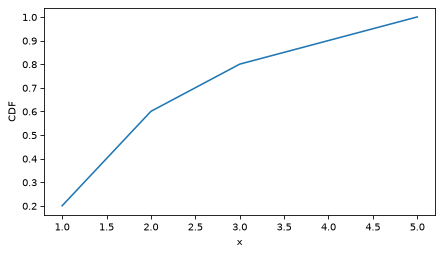

In [ ]:
from thinkstats import decorate
cdf.step()
decorate(xlabel = 'x',ylabel = 'CDF')


In [33]:
from empiricaldist import Cdf

cdf_speeds = Cdf.from_seq(speeds)

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

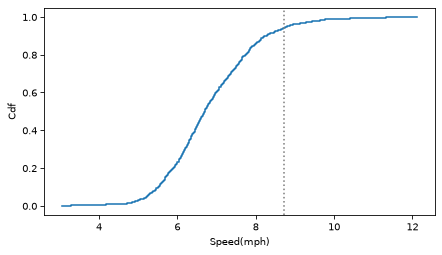

In [37]:
cdf_speeds.step()
plt.axvline(my_speed, ls =":", color = "gray")
decorate(xlabel = "Speed(mph)", ylabel = "Cdf")

In [39]:
cdf_speeds(my_speed) * 100

np.float64(94.12124923453766)

In [40]:
cdf_speeds.inverse(0.5)

array(6.70391061)

In [41]:
try:
    import statadict
except ImportError:
    %pip install statadict

In [42]:
from nsfg import get_nsfg_groups

live, firsts, others = get_nsfg_groups()

/home/axiuc-fedor/think-stats/notebooks/nsfg.py:220: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["totalwgt_lb"] = df.birthwgt_lb + df.birthwgt_oz / 16.0


In [43]:
first_weights = firsts["totalwgt_lb"].dropna()
first_weights.mean()

np.float64(7.201094430437772)

In [44]:
other_weights = others["totalwgt_lb"].dropna()
other_weights.mean()

np.float64(7.325855614973262)

In [45]:
from empiricaldist import Pmf

first_pmf = Pmf.from_seq(first_weights, name = "first")
other_pmf = Pmf.from_seq(other_weights, name = "other")

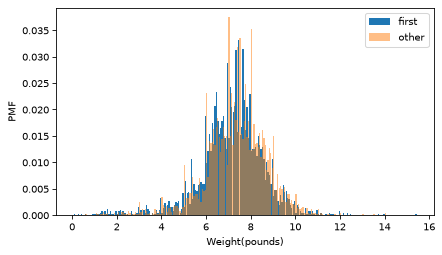

In [46]:
from thinkstats import two_bar_plots

two_bar_plots(first_pmf, other_pmf, width = 0.06)
decorate(xlabel = "Weight(pounds)", ylabel = "PMF")

In [47]:
first_cdf = first_pmf.make_cdf()
other_cdf = other_pmf.make_cdf()

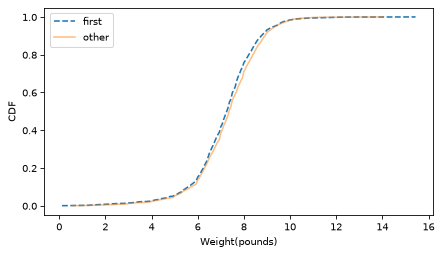

In [49]:
first_cdf.plot(ls='--')
other_cdf.plot(alpha=0.5)
decorate(xlabel = "Weight(pounds)", ylabel = "CDF")